# 1.

In [1]:
import pandas as pd

df = pd.read_csv("data/GSE72056_melanoma_single_cell_revised_v2.txt.gz", sep="\t", index_col=0)
print(df.shape)
df.iloc[:6, :4]

(23689, 4645)


,Cy72_CD45_H02_S758_comb,CY58_1_CD45_B02_S974_comb,Cy71_CD45_D08_S524_comb,Cy81_FNA_CD45_B01_S301_comb
Cell,,,,
tumor,72.0000,58.0000,71.0000,81.0000
"malignant(1=no,2=yes,0=unresolved)",1.0000,1.0000,2.0000,2.0000
"non-malignant cell type (1=T,2=B,3=Macro.4=Endo.,5=CAF;6=NK)",2.0000,1.0000,0.0000,0.0000
C9orf152,0.0000,0.0000,0.0000,0.0000
RPS11,9.2172,8.3745,9.3130,7.8876
ELMO2,0.0000,0.0000,2.1263,0.0000


In [2]:
labels = df.iloc[:3]
genes = df.iloc[3:]
print(labels.shape, genes.shape)

(3, 4645) (23686, 4645)


In [3]:
key = labels.T
key.columns = ["tumor", "malignant", "cell_type"]
key["malignant"].value_counts()

malignant
1.0    3256
2.0    1257
0.0     132
Name: count, dtype: int64

In [4]:
key["cell_type"].value_counts()


cell_type
1.0    2068
0.0    1758
2.0     515
3.0     126
4.0      65
5.0      61
6.0      52
Name: count, dtype: int64

# 2. 

`X`: the numbers, cells as rows, genes as columns \
`obs`: info about each cell (our answer key goes here) \
`var`: info about each gene

In [5]:
import anndata as ad 
import scanpy as sc
adata = ad.AnnData(X = genes.T.values.astype("float32"))       # flip to cells x genes
adata.obs_names = genes.columns # cell names
adata.var_names = genes.index   # gene names
adata.var_names_make_unique()   # some gene names repeat; this adds -1, -2 to duplicates

adata.obs["tumor"] = key["tumor"].values
adata.obs["malignant"] = key["malignant"].values
adata.obs["cell_type"] = key["cell_type"].values 

adata

AnnData object with n_obs × n_vars = 4645 × 23686
    obs: 'tumor', 'malignant', 'cell_type'
    layers: None (.X)

In [6]:
sc.pp.highly_variable_genes(adata, n_top_genes = 2000)
adata.var["highly_variable"].sum()

np.int64(2000)

In [7]:
adata.var.loc["PTPRC", "highly_variable"]

np.False_

In [8]:
import numpy as np
ptprc = adata[:, "PTPRC"].X.flatten()
for code, name in [(1, "normal"), (2, "cancer")]:
    mask = adata.obs["malignant"] == code
    print(name, "average PTPRC:", round(float(np.mean(ptprc[mask])), 2))
    

normal average PTPRC: 5.23
cancer average PTPRC: 0.21


In [9]:
score = adata.var.loc["PTPRC", "dispersions_norm"]
rank = (adata.var["dispersions_norm"] > score).sum() + 1
print("PTPRC variability rank:", rank, "of", adata.n_vars)


PTPRC variability rank: 17374 of 23686


In [10]:
markers = ["PTPRC",           # immune (CD45)
           "CD3E",            # T cells
           "CD19",            # B cells
           "CD14",            # macrophages
           "NKG7",            # NK cells
           "PECAM1",          # endothelial
           "COL1A1",          # fibroblasts (CAF)
           "MLANA", "PMEL"]   # melanoma cells

markers = [g for g in markers if g in adata.var_names]   # keep only genes present in the data
adata.var.loc[markers, "highly_variable"] = True
adata.var["highly_variable"].sum()

np.int64(2007)

/Users/dariastrait/venvs/qproj/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


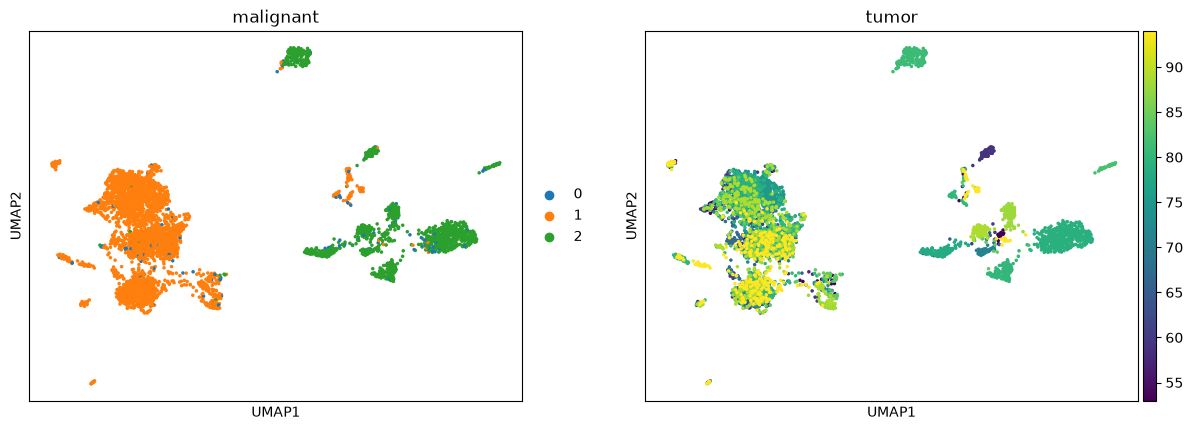

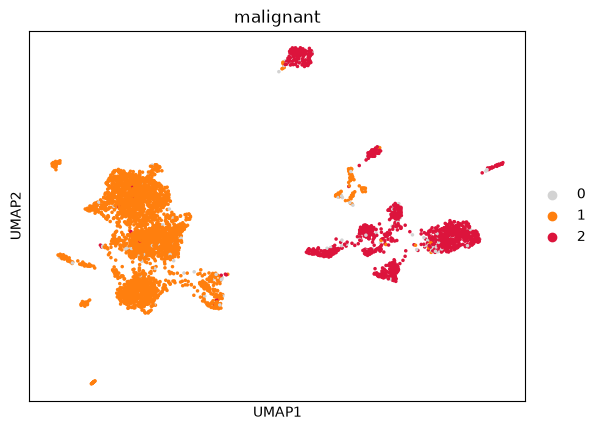

In [11]:
adata_hv = adata[:, adata.var["highly_variable"]].copy()
sc.pp.pca(adata_hv, n_comps=50)
sc.pp.neighbors(adata_hv)
sc.tl.umap(adata_hv)

adata_hv.obs["malignant"] = adata_hv.obs["malignant"].astype(int).astype(str)   # so colors are categories, not a gradient
sc.pl.umap(adata_hv, color=["malignant", "tumor"])
sc.pl.umap(adata_hv, color="malignant",
           palette={"0": "lightgray", "1": "tab:orange", "2": "crimson"})

In [12]:
adata.obs["tumor"].nunique()

19

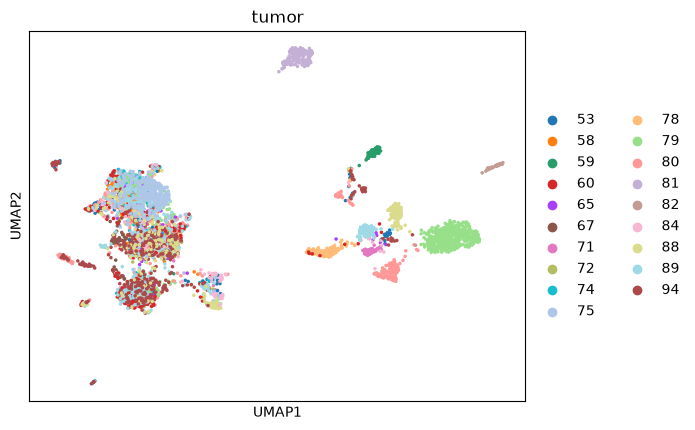

In [13]:
adata_hv.obs["tumor"] = adata_hv.obs["tumor"].astype(int).astype(str)
sc.pl.umap(adata_hv, color="tumor")

In [14]:
names = {0: "cancer/unknown", 1: "T", 2: "B", 3: "Macrophage", 4: "Endothelial", 5: "CAF", 6: "NK"}
mal = adata_hv.obs["malignant"].astype(int)
ct = adata_hv.obs["cell_type"].astype(int).map(names)

adata_hv.obs["label"] = np.where(mal == 2, "cancer",
                        np.where(mal == 0, "unresolved", ct))
adata_hv.obs["label"] = adata_hv.obs["label"].astype("category")
adata_hv.obs["label"].value_counts()

label
T                 2040
cancer            1257
B                  512
cancer/unknown     416
unresolved         132
Macrophage         119
Endothelial         62
CAF                 56
NK                  51
Name: count, dtype: int64

/Users/dariastrait/venvs/qproj/lib/python3.13/site-packages/sklearn/manifold/_isomap.py:386: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
/Users/dariastrait/venvs/qproj/lib/python3.13/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


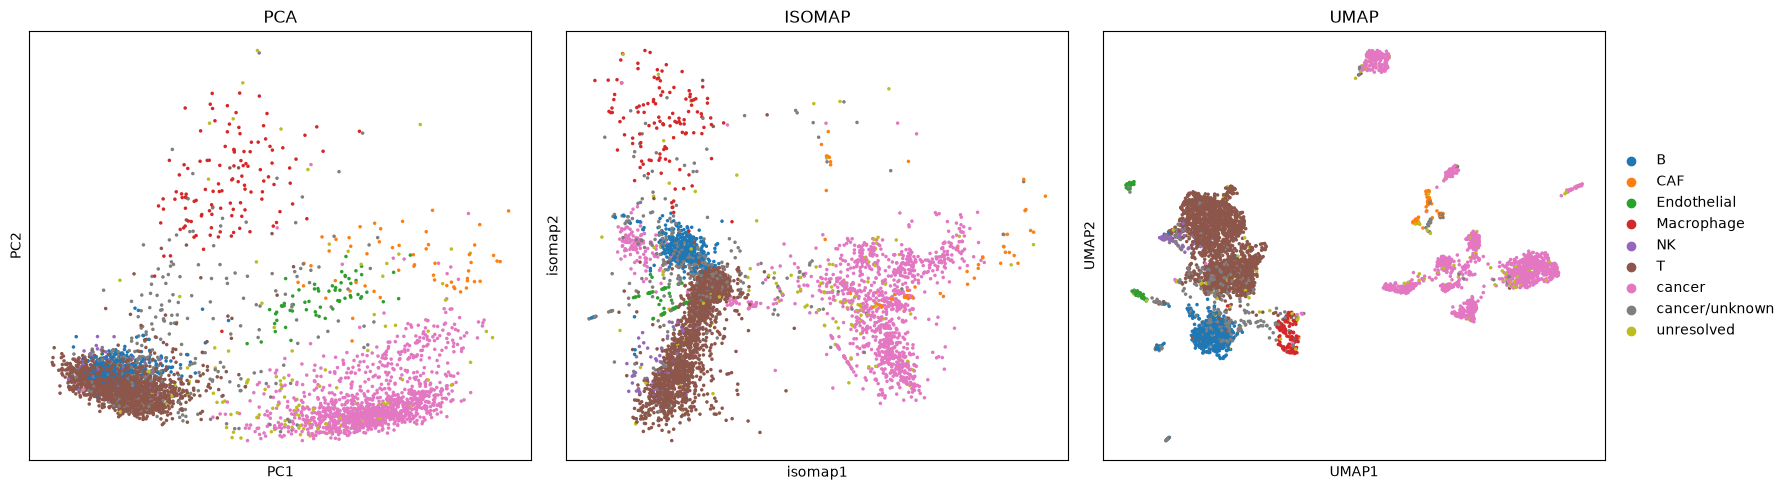

In [15]:
from sklearn.manifold import Isomap

# Isomap on the 50 PCA dimensions (faster, less noisy than 2,007 genes)
adata_hv.obsm["X_isomap"] = Isomap(n_components=2, n_neighbors=5).fit_transform(adata_hv.obsm["X_pca"])

# readable cell-type names instead of codes
names = {0: "cancer/unknown", 1: "T", 2: "B", 3: "Macrophage", 4: "Endothelial", 5: "CAF", 6: "NK"}
adata_hv.obs["type_name"] = adata_hv.obs["cell_type"].astype(int).map(names).astype("category")

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, basis in zip(axes, ["pca", "isomap", "umap"]):
    sc.pl.embedding(adata_hv, basis=basis, color="label", ax=ax, show=False,
                    title=basis.upper(), legend_loc=None if basis != "umap" else "right margin")
plt.tight_layout()
plt.show()

In [16]:
adata.obs["tumor"].value_counts().sort_index()


tumor
53.0    143
58.0    142
59.0     70
60.0    226
65.0     63
67.0     95
71.0     89
72.0    181
74.0    147
75.0    344
78.0    131
79.0    896
80.0    480
81.0    205
82.0     84
84.0    159
88.0    351
89.0    475
94.0    364
Name: count, dtype: int64

In [17]:
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    adata_hv.obs_names,
    test_size=0.5,
    random_state=42,
    stratify=adata_hv.obs["cell_type"]   # same mix of cell types in both halves
)
print(len(train_idx), len(test_idx))

2322 2323


In [18]:
train = adata_hv[train_idx].copy()
train = train[train.obs["malignant"] != "0"].copy()    # drop unresolved

sc.tl.rank_genes_groups(train, groupby="malignant", method="wilcoxon")

top_cancer = sc.get.rank_genes_groups_df(train, group="2").head(8)
top_normal = sc.get.rank_genes_groups_df(train, group="1").head(8)
print(top_cancer[["names", "logfoldchanges"]])
print(top_normal[["names", "logfoldchanges"]])

   names  logfoldchanges
0  SPARC        8.165022
1   APOD       11.274310
2  CALD1        5.115206
3   PMEL       11.004420
4  TIMP1        7.593268
5  MLANA        6.295465
6  CTSL1        6.381712
7  CCND1        5.511422
      names  logfoldchanges
0     PTPRC        9.742161
1      CD74        8.514390
2      CD3E        8.669606
3  UGDH-AS1        1.819843
4       LYZ        2.384093
5     CABP4        1.652525
6   MAB21L3        1.773596
7     CCL22        1.649688


In [19]:
candidates = list(top_cancer["names"]) + list(top_normal["names"])
expr = train[:, candidates].X
corr = np.corrcoef(expr.T)            # 16 × 16 table: how alike each pair is
pd.DataFrame(corr, index=candidates, columns=candidates).round(2)

,SPARC,APOD,CALD1,PMEL,TIMP1,MLANA,CTSL1,CCND1,PTPRC,CD74,CD3E,UGDH-AS1,LYZ,CABP4,MAB21L3,CCL22
SPARC,1.00,0.70,0.73,0.58,0.74,0.51,0.62,0.61,-0.74,-0.57,-0.48,-0.37,-0.32,-0.36,-0.31,-0.31
APOD,0.70,1.00,0.56,0.72,0.70,0.63,0.62,0.57,-0.67,-0.49,-0.44,-0.33,-0.29,-0.30,-0.31,-0.27
CALD1,0.73,0.56,1.00,0.51,0.64,0.46,0.57,0.55,-0.68,-0.54,-0.45,-0.28,-0.26,-0.30,-0.23,-0.24
PMEL,0.58,0.72,0.51,1.00,0.49,0.82,0.53,0.61,-0.59,-0.48,-0.39,-0.27,-0.26,-0.27,-0.23,-0.23
TIMP1,0.74,0.70,0.64,0.49,1.00,0.42,0.69,0.55,-0.65,-0.45,-0.44,-0.38,-0.13,-0.32,-0.32,-0.26
MLANA,0.51,0.63,0.46,0.82,0.42,1.00,0.46,0.56,-0.56,-0.47,-0.37,-0.15,-0.20,-0.16,-0.13,-0.13
CTSL1,0.62,0.62,0.57,0.53,0.69,0.46,1.00,0.55,-0.59,-0.41,-0.42,-0.31,-0.10,-0.30,-0.28,-0.22
CCND1,0.61,0.57,0.55,0.61,0.55,0.56,0.55,1.00,-0.58,-0.43,-0.40,-0.31,-0.22,-0.28,-0.25,-0.24
PTPRC,-0.74,-0.67,-0.68,-0.59,-0.65,-0.56,-0.59,-0.58,1.00,0.52,0.59,0.34,0.29,0.33,0.30,0.27
CD74,-0.57,-0.49,-0.54,-0.48,-0.45,-0.47,-0.41,-0.43,0.52,1.00,0.19,0.17,0.30,0.20,0.17,0.18


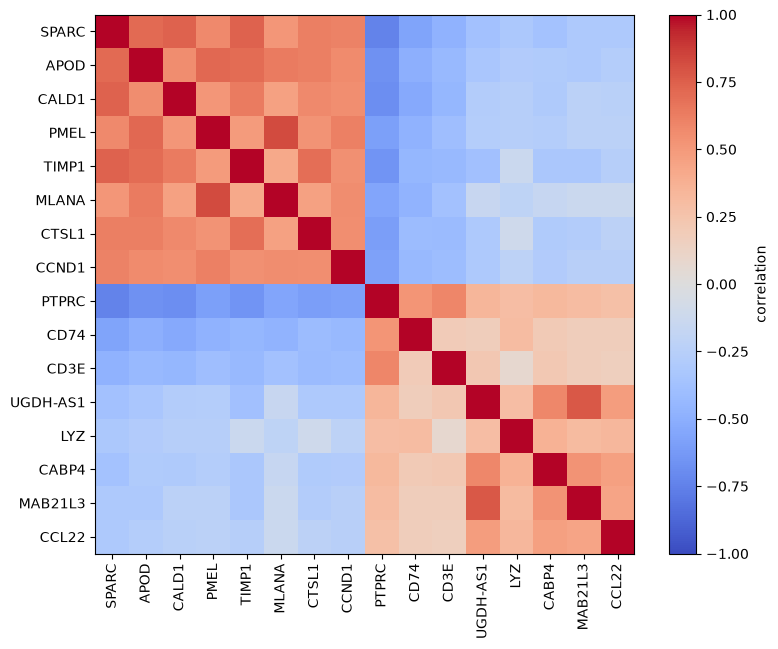

In [20]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(16), candidates, rotation=90)
plt.yticks(range(16), candidates)
plt.colorbar(label="correlation")
plt.show()

In [21]:
corr_df = pd.DataFrame(corr, index=candidates, columns=candidates)
corr_df.loc["PMEL", "MLANA"]

np.float64(0.8213721806156893)

In [22]:
y = (train.obs["malignant"] == "2").astype(int).values   # 1 = cancer, 0 = normal

r = np.array([abs(np.corrcoef(expr[:, i], y)[0, 1]) for i in range(len(candidates))])

pd.Series(r, index=candidates).round(2).sort_values(ascending=False)

APOD        0.82
SPARC       0.78
PMEL        0.78
PTPRC       0.76
MLANA       0.72
TIMP1       0.67
CALD1       0.66
CCND1       0.65
CTSL1       0.64
CD74        0.63
CD3E        0.50
CABP4       0.38
UGDH-AS1    0.37
LYZ         0.36
MAB21L3     0.34
CCL22       0.32
dtype: float64

## 3. Building the QUBO

**Goal:** choose a small panel of k genes that separates cancer from normal cells.

Each gene gets a yes/no variable xᵢ (1 = in the panel). The QUBO score is:
- **reward** −rᵢ for each chosen gene (how well it follows the cancer/normal label)
- **redundancy penalty** α·|Rᵢⱼ| for each chosen pair (genes that say the same thing)
- **size penalty** λ(Σxᵢ − k)², so the panel has exactly k genes

Settings for the first run: k = 2, α = 1, λ = 2 (λ is larger than any single reward, like M in Homework 1).

In [23]:
n = len(candidates)
k, alpha, lam = 2, 1.0, 2.0

R = np.abs(corr)                 # redundancy: how alike two genes are (0 to 1)
np.fill_diagonal(R, 0)           # a gene is not "redundant with itself"

Q = np.zeros((n, n))
Q += alpha * R / 2               # redundancy, split across Q[i,j] and Q[j,i]
Q += lam * (np.ones((n, n)) - np.eye(n))   # the 2λ per pair, split as λ + λ
Q[np.diag_indices(n)] += -r + lam * (1 - 2 * k)   # reward + λ(1-2k) on the diagonal

const = lam * k**2
print(Q.shape, const)

(16, 16) 8.0


## 4. Exact solution by brute force

With 16 candidate genes there are 2¹⁶ = 65,536 possible panels, so we can check every one and find the true best panel.
This is the exact answer that CPLEX and QAOA will be compared against.

**Result:** the QUBO chose **SPARC + MLANA**, not APOD + PTPRC.
APOD and PTPRC are mirror images (correlation −0.67), and the |R| penalty treats mirror images as redundant.

In [24]:
import itertools

best_score, best_x = None, None
for bits in itertools.product([0, 1], repeat=n):
    x = np.array(bits)
    score = x @ Q @ x + const
    if best_score is None or score < best_score:
        best_score, best_x = score, x

chosen = [candidates[i] for i in range(n) if best_x[i] == 1]
print("best score:", round(best_score, 3))
print("chosen genes:", chosen)

best score: -0.999
chosen genes: ['SPARC', 'MLANA']


## 5. Do the panels actually work? (test half)

The real check: train a simple classifier (logistic regression) on each panel using the **training** cells,
then score it on the **test** cells it has never seen.

**Score:** balanced accuracy, the average of "% of cancer cells correctly found" and "% of normal cells correctly found".
We use it because normal cells outnumber cancer cells, so plain accuracy could look good just by guessing "normal".

Panels compared:
- the QUBO's choice (SPARC + MLANA)
- my biology choice (APOD + PTPRC)
- the simple baseline: top-2 genes by relevance alone (APOD + SPARC)

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

test = adata_hv[test_idx].copy()
test = test[test.obs["malignant"] != "0"].copy()          # drop unresolved, same as training
y_test = (test.obs["malignant"] == "2").astype(int).values

def evaluate(panel):
    model = LogisticRegression().fit(train[:, panel].X, y)   # learn on training cells
    pred = model.predict(test[:, panel].X)                    # guess on unseen test cells
    return balanced_accuracy_score(y_test, pred)

panels = {
    "QUBO: SPARC + MLANA":           chosen,
    "Dasha: APOD + PTPRC":           ["APOD", "PTPRC"],
    "Top-2 relevance: APOD + SPARC": ["APOD", "SPARC"],
}
for name, panel in panels.items():
    print(f"{name:32s} {evaluate(panel):.3f}")

QUBO: SPARC + MLANA              0.906
Dasha: APOD + PTPRC              0.928
Top-2 relevance: APOD + SPARC    0.901


**Result:** my biology pick (APOD + PTPRC, 0.928) beat the QUBO's pick (SPARC + MLANA, 0.906)
and the top-2 baseline (0.901). The QUBO avoided APOD + PTPRC because |R| treats
mirror-image genes (correlation −0.67) as redundant, but they come from different cell types
and complement each other. Next: penalize only positive correlation, and repeat with other splits.

In [26]:
R2 = np.clip(corr, 0, None)        # keep only positive correlation (genes going up together)
np.fill_diagonal(R2, 0)

Q2 = np.zeros((n, n))
Q2 += alpha * R2 / 2
Q2 += lam * (np.ones((n, n)) - np.eye(n))
Q2[np.diag_indices(n)] += -r + lam * (1 - 2 * k)

best_score2, best_x2 = None, None
for bits in itertools.product([0, 1], repeat=n):
    x = np.array(bits)
    score = x @ Q2 @ x + const
    if best_score2 is None or score < best_score2:
        best_score2, best_x2 = score, x

chosen2 = [candidates[i] for i in range(n) if best_x2[i] == 1]
print("best score:", round(best_score2, 3))
print("chosen genes:", chosen2)
print("test score:", round(evaluate(chosen2), 3))

best score: -1.583
chosen genes: ['APOD', 'PTPRC']
test score: 0.928


**Result:** with the positive-only redundancy rule, the QUBO picks APOD + PTPRC
(score −1.583), the same panel as my biology choice, with the best test score (0.928).
Caveat: the rule was changed after seeing test results, so it should be confirmed
on new train/test splits or on a new task before trusting it.